In [1]:
# 데이터 경로 (new_joints/, texts/ 가 들어 있는 폴더)
DATA_ROOT = '/home/jaesik/mnt/HumanML3D/HumanML3D'

# ===== 판정 임계값 (높이 단위 m, 모두 클립 바닥 기준) =====
# 서 있을 때 발목 높이. 정지 상태로 발가락이 바닥에 닿은 프레임의 발목 높이 중앙값(0.059 m)에서 잡음
STANDING_ANKLE_HEIGHT = 0.06
# 발목 판정의 여유값
ANKLE_MARGIN = 0.03
# 발가락 판정의 여유값
TOE_MARGIN = 0.03
# 발목의 프레임 간 이동량 임계값 (m/프레임). HumanML3D의 feet_thre=0.002 (이동량 제곱 합) → sqrt(0.002)
ANKLE_DISP_THRESH = 0.0447

# ===== 키워드 (정규식, 대소문자 무시) =====
# 단순 부분 문자열로 찾으면 run이 drunk/trunk에도 걸리고, on toes는 on his toes를 놓쳐서 단어 패턴으로 지정
KEYWORD_PATTERNS = {
    'tiptoe':  r'\btip[\s-]*toe\w*|\btippy[\s-]*toe\w*|\btips[\s-]*toes?\b',
    'on toes': r'\bon\s+(?:(?:his|her|their|its|the|one|both|left|right|tip|tippy|tips)\s+){0,3}toes?\b',
    'stairs':  r'\w*stair\w*',
    'run':     r'\b(?:run|runs|running|runing|ran)\b',
    'jump':    r'\w*jump\w*',
    'squat':   r'\bsquat\w*',
    'kneel':   r'\bkneel\w*|\bknelt\b',
}

# ===== 출력 설정 =====
# 전체 프레임 표에서 노트북에 출력할 행 수
MAX_TABLE_ROWS = 50
# 키워드마다 시각화할 클립 수와 시작 순위 (0이면 1위부터)
VIS_PER_KEYWORD = 2
VIS_RANK_START = 0
# 표를 CSV로 저장할지 여부와 저장 폴더
SAVE_CSV = True
OUTPUT_DIR = '/home/jaesik/mnt/Motion-Data-Analysis/draft/outputs'
# 표에서 고른 클립을 따로 볼 때 이름 입력 (예: '012314'), None이면 건너뜀
INSPECT_CLIP = None

# ===== 시각화 설정 =====
# 그래프 세로축 상한 (m). 바닥 근처를 보기 위한 값이고, 이보다 높은 구간은 잘려 보임
PLOT_YMAX = 0.40
# 프레임 이미지 장수
N_KEY_FRAMES = 6
# 후보 구간 앞뒤로 함께 보여줄 프레임 수
SEGMENT_PAD = 8
# 클립마다 보여줄 구간 수 (긴 구간부터)
VIS_SEGMENTS_PER_CLIP = 1
# 구간별 표에 출력할 최대 행 수
MAX_ROWS_PER_SEGMENT = 20
# 애니메이션 포함 여부, 재생 속도(원본 20fps), 최대 프레임 수
ANIMATE = True
ANIM_FPS = 10
ANIM_MAX_FRAMES = 60
# True면 이미 본 클립의 좌우 반전본(M...)은 시각화에서 건너뜀 (표에는 모두 나옴)
VIS_SKIP_MIRROR = True


# 키워드 클립에서 발 접촉 불일치 프레임 찾기

발가락 기준으론 접촉인데 발목 기준으론 공중인 프레임을 키워드 클립에서 찾습니다. 임계값은 맨 위 셀에서 조절합니다.

**표의 열**: `clip` 클립 이름 · `foot` 발(L/R) · `frame` 프레임 번호 · `text` 그 프레임을 설명하는 캡션 · `ankle_h`, `toe_h` 바닥 기준 발목·발가락 높이(m) · `ankle_disp` 발목 이동량(m/프레임) · `ankle_fail` 발목 판정이 실패한 이유(`height` 높이 초과 / `motion` 이동량 초과 / `height+motion` 둘 다) · `in_text_span` 표시된 캡션이 이 프레임 구간을 설명하면 True (HumanML3D 캡션 일부는 클립의 일부 구간만 설명함)

**발가락 관절**: 10·11번은 발 끝이 아니라 발볼 위치의 관절입니다.

In [2]:
import os
import glob
import re
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# 데이터 프레임 속도
FPS = 20
# 발별 (발목, 발가락) 관절 번호
FEET = {'L': (7, 10), 'R': (8, 11)}
# 발별 (무릎, 발목, 발가락) 관절 번호. 발 확대 그림에 사용
FOOT_CHAIN = {'L': [4, 7, 10], 'R': [5, 8, 11]}
# 바닥 계산에 쓰는 발 관절
FOOT_JOINTS = [7, 8, 10, 11]
# 22관절 골격의 뼈대 연결
CHAINS = [[0, 2, 5, 8, 11], [0, 1, 4, 7, 10], [0, 3, 6, 9, 12, 15],
          [9, 14, 17, 19, 21], [9, 13, 16, 18, 20]]

# 임계값에서 계산한 높이 상한
ANKLE_HEIGHT_LIMIT = STANDING_ANKLE_HEIGHT + ANKLE_MARGIN
TOE_HEIGHT_LIMIT = TOE_MARGIN

# 그림 색상 (발목/발가락은 모든 그림에서 같은 색)
COLOR_ANKLE, COLOR_TOE = '#2a78d6', '#eb6834'
INK, INK_SOFT, BONE, GRID, SURFACE = '#0b0b0b', '#52514e', '#b4b2a9', '#e6e4dd', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK_SOFT, 'text.color': INK,
                     'xtick.color': INK_SOFT, 'ytick.color': INK_SOFT, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'animation.embed_limit': 100})
pd.set_option('display.max_colwidth', 90)


def load_joints(names):
    """클립 이름 목록의 관절 위치를 불러옴. {이름: (T, 22, 3)}"""
    with ThreadPoolExecutor(16) as ex:
        arrays = list(ex.map(lambda n: np.load(f'{DATA_ROOT}/new_joints/{n}.npy'), names))
    return dict(zip(names, arrays))


def load_captions(name):
    """텍스트 파일 한 개를 읽음. start/end는 초 단위이고 둘 다 0이면 클립 전체를 설명"""
    captions = []
    path = f'{DATA_ROOT}/texts/{name}.txt'
    if not os.path.exists(path):
        return captions
    with open(path, encoding='utf-8') as f:
        for line in f:
            parts = line.rstrip('\n').split('#')
            if len(parts) >= 4 and parts[0].strip():
                # 구간 값이 nan인 줄이 있어서 클립 전체(0)로 처리 (HumanML3D 로더와 동일)
                start, end = np.nan_to_num([float(parts[-2]), float(parts[-1])])
                captions.append({'text': parts[0].strip(), 'start': start, 'end': end})
    return captions


def analyze_clip(joints):
    """클립 한 개에 판정을 적용. 프레임 수가 2 미만이면 이동량을 구할 수 없어 None"""
    if len(joints) < 2:
        return None
    # 바닥: 클립 전체에서 발 관절(발목·발가락 양쪽)의 최저 높이
    floor = joints[:, FOOT_JOINTS, 1].min()
    result = {'floor': floor}
    for foot, (ankle_i, toe_i) in FEET.items():
        ankle_h = joints[:, ankle_i, 1] - floor
        toe_h = joints[:, toe_i, 1] - floor
        # 프레임 t의 이동량 = t → t+1 발목 이동 거리(3D). 마지막 프레임은 직전 값을 사용
        disp = np.linalg.norm(np.diff(joints[:, ankle_i], axis=0), axis=1)
        disp = np.append(disp, disp[-1])
        ankle_low = ankle_h <= ANKLE_HEIGHT_LIMIT
        ankle_still = disp <= ANKLE_DISP_THRESH
        ankle_contact = ankle_low & ankle_still
        toe_contact = toe_h <= TOE_HEIGHT_LIMIT
        # 찾는 대상: 발가락 기준 접촉 & 발목 기준 공중
        target = toe_contact & ~ankle_contact
        # 발목 판정이 실패한 이유
        fail = np.where(~ankle_low & ~ankle_still, 'height+motion', np.where(~ankle_low, 'height', 'motion'))
        result[foot] = {'ankle_h': ankle_h, 'toe_h': toe_h, 'disp': disp, 'target': target,
                        'ankle_contact': ankle_contact, 'toe_contact': toe_contact, 'fail': fail}
    return result


def frame_captions(captions, n_frames):
    """프레임마다 그 프레임을 설명하는 첫 캡션 번호를 구함. 맞는 캡션이 없으면 0번과 False"""
    cap_i = np.zeros(n_frames, dtype=int)
    covered = np.zeros(n_frames, dtype=bool)
    for i in range(len(captions) - 1, -1, -1):
        c = captions[i]
        if c['start'] == 0 and c['end'] == 0:
            mask = np.ones(n_frames, dtype=bool)
        else:
            mask = np.zeros(n_frames, dtype=bool)
            mask[int(c['start'] * FPS):int(c['end'] * FPS)] = True
        cap_i[mask] = i
        covered |= mask
    return cap_i, covered


def build_frame_table(clips, joints, captions):
    """찾는 대상 프레임을 모두 모아 표로 만듦. 한 행 = (클립, 발, 프레임)"""
    cols = {k: [] for k in ['clip_i', 'foot', 'frame', 'text', 'ankle_h', 'toe_h',
                            'ankle_disp', 'ankle_fail', 'in_text_span']}
    for i, clip in enumerate(clips):
        result = analyze_clip(joints[clip])
        if result is None:
            continue
        caps = captions[clip]
        cap_i, covered = frame_captions(caps, len(joints[clip]))
        texts = np.array([c['text'] for c in caps] or [''], dtype=object)
        for foot in FEET:
            r = result[foot]
            idx = np.flatnonzero(r['target'])
            if idx.size == 0:
                continue
            cols['clip_i'].append(np.full(idx.size, i))
            cols['foot'].append(np.full(idx.size, foot))
            cols['frame'].append(idx)
            cols['text'].append(texts[cap_i[idx]])
            cols['ankle_h'].append(r['ankle_h'][idx])
            cols['toe_h'].append(r['toe_h'][idx])
            cols['ankle_disp'].append(r['disp'][idx])
            cols['ankle_fail'].append(r['fail'][idx])
            cols['in_text_span'].append(covered[idx])
    if not cols['clip_i']:
        return pd.DataFrame(columns=['clip', 'foot', 'frame', 'text', 'ankle_h', 'toe_h',
                                     'ankle_disp', 'ankle_fail', 'in_text_span'])
    data = {k: np.concatenate(v) for k, v in cols.items()}
    names = np.array(clips, dtype=object)
    df = pd.DataFrame({'clip': names[data['clip_i']], **{k: data[k] for k in cols if k != 'clip_i'}})
    return df.sort_values(['clip', 'foot', 'frame']).reset_index(drop=True)


def rank_clips(df, joints, captions):
    """클립별 대상 프레임 수 표. n_target은 왼발+오른발 프레임 합이라 n_frames의 2배까지 가능"""
    by_foot = df.groupby(['clip', 'foot']).size().unstack(fill_value=0).reindex(columns=['L', 'R'], fill_value=0)
    rank = pd.DataFrame({'n_target': by_foot.sum(axis=1), 'n_target_L': by_foot['L'], 'n_target_R': by_foot['R']})
    rank['n_frames'] = [len(joints[c]) for c in rank.index]
    rank['target_ratio'] = (rank['n_target'] / (2 * rank['n_frames'])).round(3)
    rank['n_height_fail'] = (df['ankle_fail'] != 'motion').groupby(df['clip']).sum()
    rank['n_motion_only'] = rank['n_target'] - rank['n_height_fail']
    rank['text'] = [captions[c][0]['text'] if captions[c] else '' for c in rank.index]
    rank = rank.reset_index().sort_values(['n_target', 'clip'], ascending=[False, True]).reset_index(drop=True)
    rank.insert(0, 'rank', rank.index + 1)
    return rank


def find_segments(mask):
    """불리언 배열에서 연속 True 구간 [(시작, 끝), ...] (끝은 미포함)"""
    edges = np.flatnonzero(np.diff(np.r_[0, mask.astype(np.int8), 0]))
    return list(zip(edges[::2].tolist(), edges[1::2].tolist()))


def body_axis(joints, foot, lo, hi):
    """구간 동안 발이 향한 평균 수평 방향. 옆모습 투영축으로 사용"""
    ankle_i, toe_i = FEET[foot]
    v = (joints[lo:hi, toe_i] - joints[lo:hi, ankle_i])[:, [0, 2]].mean(axis=0)
    n = np.linalg.norm(v)
    return v / n if n > 1e-6 else np.array([1.0, 0.0])


def project_body(joints, frame, u):
    """전신을 옆모습으로 투영. 가로축은 골반 기준 u 방향 거리"""
    p = joints[frame] - joints[frame, 0]
    return p[:, 0] * u[0] + p[:, 2] * u[1]


def project_foot(joints, frame, foot):
    """무릎·발목·발가락을 발 방향 평면에 투영. 가로축은 발목 기준 프레임별 발 방향 거리"""
    knee_i, ankle_i, toe_i = FOOT_CHAIN[foot]
    v = (joints[frame, toe_i] - joints[frame, ankle_i])[[0, 2]]
    n = np.linalg.norm(v)
    u = v / n if n > 1e-6 else np.array([1.0, 0.0])
    p = joints[frame, [knee_i, ankle_i, toe_i]] - joints[frame, ankle_i]
    return p[:, 0] * u[0] + p[:, 2] * u[1]


def draw_body(ax, joints, floor, frame, foot, u, ymax):
    """전신 스켈레톤 한 프레임을 그림. 대상 발의 다리는 진하게, 발목/발가락은 색 점으로 표시"""
    x, y = project_body(joints, frame, u), joints[frame, :, 1] - floor
    for chain in CHAINS:
        ax.plot(x[chain], y[chain], color=BONE, lw=1.6, solid_capstyle='round')
    chain = FOOT_CHAIN[foot]
    ax.plot(x[chain], y[chain], color=INK_SOFT, lw=2, solid_capstyle='round')
    ax.scatter(x[chain[1]], y[chain[1]], s=26, color=COLOR_ANKLE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.scatter(x[chain[2]], y[chain[2]], s=26, color=COLOR_TOE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.set(xlim=(-1, 1), ylim=(-0.05, ymax), aspect='equal', xticks=[], yticks=[])
    for s in ax.spines.values():
        s.set_visible(False)


def draw_foot(ax, joints, floor, frame, foot):
    """발 부분 확대 한 프레임. 점선은 발목/발가락 높이 상한"""
    x, y = project_foot(joints, frame, foot), joints[frame, FOOT_CHAIN[foot], 1] - floor
    ax.axhline(0, color=INK_SOFT, lw=1)
    ax.axhline(ANKLE_HEIGHT_LIMIT, color=COLOR_ANKLE, lw=0.8, ls=':')
    ax.axhline(TOE_HEIGHT_LIMIT, color=COLOR_TOE, lw=0.8, ls=':')
    ax.plot(x, y, color=INK_SOFT, lw=2, solid_capstyle='round')
    ax.scatter(x[1], y[1], s=36, color=COLOR_ANKLE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.scatter(x[2], y[2], s=36, color=COLOR_TOE, edgecolor=SURFACE, lw=1, zorder=5)
    ax.set(xlim=(-0.2, 0.3), ylim=(-0.03, 0.3), aspect='equal', xticks=[], yticks=[])
    for s in ax.spines.values():
        s.set_visible(False)


def plot_heights(ax, r, foot_name, seg=None, key_frames=(), show_labels=True):
    """한쪽 발의 발목·발가락 높이 그래프. 회색 띠는 대상 프레임, 진한 띠는 지금 보는 구간"""
    t = np.arange(len(r['ankle_h']))
    for s, e in find_segments(r['target']):
        ax.axvspan(s - 0.5, e - 0.5, color=BONE, alpha=0.28, lw=0)
    if seg is not None:
        ax.axvspan(seg[0] - 0.5, seg[1] - 0.5, color=BONE, alpha=0.55, lw=0)
    ax.axhline(ANKLE_HEIGHT_LIMIT, color=COLOR_ANKLE, lw=0.9, ls=':')
    ax.axhline(TOE_HEIGHT_LIMIT, color=COLOR_TOE, lw=0.9, ls=':')
    ax.axhline(0, color=INK_SOFT, lw=0.8)
    ax.plot(t, r['ankle_h'], color=COLOR_ANKLE, lw=2, label='ankle')
    ax.plot(t, r['toe_h'], color=COLOR_TOE, lw=2, label='toe')
    for f in key_frames:
        ax.axvline(f, color=INK_SOFT, lw=0.6, alpha=0.6)
    ax.set_ylim(-0.02, PLOT_YMAX)
    ax.set_xlim(-0.5, max(t[-1], 1) + 0.5)
    ax.grid(axis='y', color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(foot_name, loc='left', fontsize=10)
    ax.set_xlabel('frame (20 fps)')
    if show_labels:
        # 선 끝 직접 라벨. 두 값이 가까우면 위아래로 벌림
        ya, yt = min(r['ankle_h'][-1], PLOT_YMAX * 0.97), min(r['toe_h'][-1], PLOT_YMAX * 0.97)
        if abs(ya - yt) < 0.03:
            ya, yt = (ya + 0.018, yt - 0.018) if ya >= yt else (ya - 0.018, yt + 0.018)
        ax.annotate('ankle', (1.005, ya), xycoords=('axes fraction', 'data'), fontsize=8, va='center', color=INK_SOFT)
        ax.annotate('toe', (1.005, max(yt, -0.01)), xycoords=('axes fraction', 'data'), fontsize=8, va='center', color=INK_SOFT)


def show_segment_figure(clip, joints, result, foot, seg, text):
    """후보 구간의 프레임 이미지(전신·발 확대)와 발목·발가락 높이 그래프를 한 그림에 그림"""
    s, e = seg
    floor = result['floor']
    lo, hi = max(0, s - SEGMENT_PAD), min(len(joints), e + SEGMENT_PAD)
    keys = np.unique(np.linspace(lo, hi - 1, N_KEY_FRAMES).round().astype(int))
    u = body_axis(joints, foot, s, e)
    ymax = max(1.9, (joints[keys, :, 1] - floor).max() + 0.1)
    r = result[foot]

    fig = plt.figure(figsize=(13, 8.2))
    gs = fig.add_gridspec(3, len(keys), height_ratios=[2.2, 1.0, 1.7], hspace=0.28, wspace=0.05,
                          left=0.05, right=0.96, top=0.9, bottom=0.07)
    for col, f in enumerate(keys):
        ax = fig.add_subplot(gs[0, col])
        draw_body(ax, joints, floor, f, foot, u, ymax)
        state = 'target' if r['target'][f] else ''
        ax.set_title(f'frame {f}  {state}', fontsize=9, fontweight='bold' if state else 'normal')
        ax = fig.add_subplot(gs[1, col])
        draw_foot(ax, joints, floor, f, foot)
        ax.set_xlabel(f"ankle {r['ankle_h'][f]:.3f} / toe {r['toe_h'][f]:.3f} m", fontsize=8)
    sub = gs[2, :].subgridspec(1, 2, wspace=0.12)
    names = {'L': 'Left foot', 'R': 'Right foot'}
    first_ax = None
    for i, side in enumerate(['L', 'R']):
        ax = fig.add_subplot(sub[0, i], sharey=first_ax)
        first_ax = first_ax or ax
        plot_heights(ax, result[side], names[side], seg if side == foot else None,
                     keys if side == foot else ())
        if i == 0:
            ax.set_ylabel('height above clip floor (m)')
            handles = [plt.Line2D([], [], color=COLOR_ANKLE, lw=2, label='ankle'),
                       plt.Line2D([], [], color=COLOR_TOE, lw=2, label='toe'),
                       plt.Line2D([], [], color=COLOR_ANKLE, lw=0.9, ls=':', label=f'ankle limit {ANKLE_HEIGHT_LIMIT:.3f} m'),
                       plt.Line2D([], [], color=COLOR_TOE, lw=0.9, ls=':', label=f'toe limit {TOE_HEIGHT_LIMIT:.3f} m'),
                       plt.Rectangle((0, 0), 1, 1, color=BONE, alpha=0.4, label='target frames')]
            ax.legend(handles=handles, loc='upper left', ncols=5, frameon=False, fontsize=8)
    fig.suptitle(f'{clip}  ·  {names[foot]}  ·  frames {s}–{e - 1} ({e - s} f, {(e - s) / FPS:.2f} s)\n{text[:120]}',
                 fontsize=11, x=0.05, ha='left')
    plt.show()


def show_segment_animation(clip, joints, result, foot, seg):
    """전신·발 확대·높이 그래프를 프레임별로 재생. 슬라이더로 한 프레임씩 넘겨 볼 수 있음"""
    s, e = seg
    lo = max(0, s - SEGMENT_PAD)
    hi = min(len(joints), e + SEGMENT_PAD, lo + ANIM_MAX_FRAMES)
    frames = list(range(lo, hi))
    floor = result['floor']
    r = result[foot]
    u = body_axis(joints, foot, s, e)
    ymax = max(1.9, (joints[lo:hi, :, 1] - floor).max() + 0.1)
    chain = FOOT_CHAIN[foot]

    fig, (ax_body, ax_foot, ax_h) = plt.subplots(1, 3, figsize=(9.5, 3.4), dpi=72,
                                                 gridspec_kw={'width_ratios': [1, 1.1, 2]})
    for ax, draw in [(ax_body, lambda a: draw_body(a, joints, floor, lo, foot, u, ymax)),
                     (ax_foot, lambda a: draw_foot(a, joints, floor, lo, foot))]:
        draw(ax)
    plot_heights(ax_h, r, {'L': 'Left foot', 'R': 'Right foot'}[foot], seg, show_labels=False)
    ax_h.set_xlim(lo - 0.5, hi - 0.5)
    ax_h.legend(loc='upper right', frameon=False, fontsize=8)
    # draw_body는 뼈대 → 대상 다리 순서로, draw_foot은 수평선 3개 → 다리 순서로 선을 그림
    body_lines = ax_body.lines[:len(CHAINS)]
    body_leg = ax_body.lines[len(CHAINS)]
    body_pts = ax_body.collections[:2]
    foot_line = ax_foot.lines[3]
    foot_pts = ax_foot.collections[:2]
    cursor = ax_h.axvline(lo, color=INK, lw=1.2)
    title = fig.suptitle('', fontsize=10, x=0.02, ha='left')
    fig.tight_layout(rect=(0, 0, 1, 0.93))

    def update(f):
        x, y = project_body(joints, f, u), joints[f, :, 1] - floor
        for line, ch in zip(body_lines, CHAINS):
            line.set_data(x[ch], y[ch])
        body_leg.set_data(x[chain], y[chain])
        for pt, j in zip(body_pts, chain[1:]):
            pt.set_offsets([[x[j], y[j]]])
        fx, fy = project_foot(joints, f, foot), joints[f, chain, 1] - floor
        foot_line.set_data(fx, fy)
        for pt, i in zip(foot_pts, [1, 2]):
            pt.set_offsets([[fx[i], fy[i]]])
        cursor.set_xdata([f, f])
        state = 'TARGET' if r['target'][f] else ('both contact' if r['ankle_contact'][f] and r['toe_contact'][f] else
                                                 'ankle contact' if r['ankle_contact'][f] else 'no contact')
        title.set_text(f"{clip}  {foot}  frame {f}  [{state}]  ankle {r['ankle_h'][f]:.3f} m, toe {r['toe_h'][f]:.3f} m, "
                       f"disp {r['disp'][f]:.3f} m/f")
        return []

    anim = FuncAnimation(fig, update, frames=frames, interval=1000 / ANIM_FPS, blit=False)
    html = anim.to_jshtml(default_mode='loop')
    plt.close(fig)
    display(HTML(html))


def visualize_clip(clip, joints, captions, frame_df):
    """클립의 후보 구간을 긴 순서로 표·프레임 이미지·그래프·애니메이션으로 출력"""
    J = joints[clip]
    result = analyze_clip(J)
    if result is None:
        print(f'{clip}: 프레임 수가 2 미만이라 판정 불가')
        return
    segs = sorted(((e - s, foot, s, e) for foot in FEET for s, e in find_segments(result[foot]['target'])),
                  key=lambda v: (-v[0], v[1], v[2]))
    if not segs:
        print(f'{clip}: 찾는 대상 프레임 없음')
        return
    table = frame_df[frame_df['clip'] == clip]
    for length, foot, s, e in segs[:VIS_SEGMENTS_PER_CLIP]:
        rows = table[(table['foot'] == foot) & (table['frame'] >= s) & (table['frame'] < e)]
        note = f' (앞 {MAX_ROWS_PER_SEGMENT}행만 표시)' if len(rows) > MAX_ROWS_PER_SEGMENT else ''
        print(f'{clip} | 발 {foot} | 프레임 {s}–{e - 1} | {length}프레임{note}')
        display(rows.head(MAX_ROWS_PER_SEGMENT).round(4))
        text = rows['text'].iloc[0] if len(rows) else ''
        show_segment_figure(clip, J, result, foot, (s, e), text)
        if ANIMATE:
            show_segment_animation(clip, J, result, foot, (s, e))


def base_name(clip):
    """좌우 반전본(M...)의 원본 이름"""
    return clip[1:] if clip.startswith('M') else clip


def visualize_ranked(clips, joints, captions, frame_df, n, start=0, seen=None):
    """순위 순서로 시각화. VIS_SKIP_MIRROR면 이미 본 클립의 반전본은 건너뜀. 본 클립 집합을 돌려줌"""
    seen = set() if seen is None else seen
    shown = 0
    for clip in clips[start:]:
        if shown >= n:
            break
        if VIS_SKIP_MIRROR and base_name(clip) in seen:
            continue
        visualize_clip(clip, joints, captions, frame_df)
        seen.add(base_name(clip))
        shown += 1
    return seen


## 1. 키워드로 클립 고르기

In [3]:
# 전체 클립 이름과 캡션 불러오기
all_clips = sorted(os.path.basename(p)[:-4] for p in glob.glob(f'{DATA_ROOT}/new_joints/*.npy'))
all_captions = {c: load_captions(c) for c in all_clips}

# 키워드별 패턴 컴파일
compiled = {k: re.compile(p, re.IGNORECASE) for k, p in KEYWORD_PATTERNS.items()}
# 클립별로 일치한 키워드, 키워드별 일치 클립과 일치 캡션 수집
clip_keywords, keyword_clips, matched_captions = {}, {k: [] for k in compiled}, {}
for clip, caps in all_captions.items():
    for kw, pat in compiled.items():
        hits = [c for c in caps if pat.search(c['text'])]
        if hits:
            clip_keywords.setdefault(clip, []).append(kw)
            keyword_clips[kw].append(clip)
            matched_captions.setdefault(clip, [])
            matched_captions[clip] += [c for c in hits if c not in matched_captions[clip]]

clips = sorted(clip_keywords)
print(f'전체 {len(all_clips)}개 클립 중 키워드 일치 {len(clips)}개')
pd.DataFrame({'keyword': list(keyword_clips), 'n_clips': [len(v) for v in keyword_clips.values()]})

전체 29228개 클립 중 키워드 일치 5586개


,keyword,n_clips
0,tiptoe,96
1,on toes,64
2,stairs,646
3,run,1688
4,jump,2106
5,squat,1122
6,kneel,328


## 2. 판정 적용

표시되는 `text`는 키워드가 일치한 캡션입니다.

In [4]:
# 관절 불러오기와 판정 적용
joints = load_joints(clips)
frame_df = build_frame_table(clips, joints, matched_captions)
# 클립에 일치한 키워드 열 추가
frame_df.insert(1, 'keywords', frame_df['clip'].map(lambda c: ', '.join(clip_keywords[c])))
print(f'대상 프레임 {len(frame_df):,}개 (발 단위), 대상 프레임이 있는 클립 {frame_df["clip"].nunique():,}개')
print('발목 판정 실패 이유:', frame_df['ankle_fail'].value_counts().to_dict())

# 키워드별 요약
summary = []
for kw, kw_clips in keyword_clips.items():
    sub = frame_df[frame_df['clip'].isin(set(kw_clips))]
    summary.append({'keyword': kw, 'n_clips': len(kw_clips), 'n_clips_with_target': sub['clip'].nunique(),
                    'n_target_frames': len(sub), 'n_height_fail': int((sub['ankle_fail'] != 'motion').sum()),
                    'n_motion_only': int((sub['ankle_fail'] == 'motion').sum())})
display(pd.DataFrame(summary))

# 클립별 순위 표. 대상 프레임이 많은 순
rank = rank_clips(frame_df, joints, matched_captions)
rank.insert(2, 'keywords', rank['clip'].map(lambda c: ', '.join(clip_keywords[c])))
rank.head(MAX_TABLE_ROWS)

대상 프레임 125,789개 (발 단위), 대상 프레임이 있는 클립 5,115개
발목 판정 실패 이유: {'height': 87905, 'height+motion': 23292, 'motion': 14592}


,keyword,n_clips,n_clips_with_target,n_target_frames,n_height_fail,n_motion_only
0,tiptoe,96,94,4598,4353,245
1,on toes,64,62,4547,4479,68
2,stairs,646,597,3626,3144,482
3,run,1688,1620,37659,31041,6618
4,jump,2106,2082,45046,38083,6963
5,squat,1122,822,32924,32004,920
6,kneel,328,293,9038,8779,259


,rank,clip,keywords,n_target,n_target_L,n_target_R,n_frames,target_ratio,n_height_fail,n_motion_only,text
0,1,013577,squat,440,220,220,220,1.000,440,0,"a person is squatting, they appear to be cleaning something"
1,2,M013577,squat,440,220,220,220,1.000,440,0,"a person is squatting, they appear to be cleaning something"
2,3,M010541,squat,422,211,211,211,1.000,422,0,"a person is squat down slowly raising his right arm up, then fully raising up towards ..."
3,4,010541,squat,417,206,211,211,0.988,417,0,"a person is squat down slowly raising his left arm up, then fully raising up towards h..."
4,5,012459,squat,398,199,199,199,1.000,398,0,"a person in a squatting position, tilts and object back and forth"
5,6,M012459,squat,396,197,199,199,0.995,396,0,"a person in a squatting position, tilts and object back and forth"
6,7,M011969,squat,338,167,171,171,0.988,338,0,a man squats while bringing an object to his face with his right hand.
7,8,011969,squat,337,171,166,171,0.985,337,0,a man squats while bringing an object to his face with his left hand.
8,9,M007040,"tiptoe, on toes, jump",295,161,134,199,0.741,295,0,the person jumped up and it’s holding his hands up trying to reach for something on hi...
9,10,007040,"tiptoe, on toes, jump",282,122,160,199,0.709,282,0,the person jumped up and it’s holding his hands up trying to reach for something on hi...


In [5]:
# 프레임 단위 후보 표
print(f'전체 {len(frame_df):,}행 중 앞 {MAX_TABLE_ROWS}행 출력')
display(frame_df.head(MAX_TABLE_ROWS).round(4))

# 전체 표는 파일로 저장
if SAVE_CSV:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    frame_df.round(4).to_csv(f'{OUTPUT_DIR}/keyword_search_frames.csv.gz', index=False)
    rank.to_csv(f'{OUTPUT_DIR}/keyword_search_clips.csv', index=False)
    print('저장:', OUTPUT_DIR)

전체 125,789행 중 앞 50행 출력


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
0,000001,"jump, squat",L,19,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.0990,0.0282,0.0118,height,True
1,000001,"jump, squat",L,21,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1214,0.0251,0.0367,height,True
2,000001,"jump, squat",L,31,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1373,0.0259,0.0068,height,True
3,000001,"jump, squat",L,32,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1366,0.0298,0.0115,height,True
4,000001,"jump, squat",R,5,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1032,0.0235,0.0295,height,True
5,000001,"jump, squat",R,8,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.0898,0.0218,0.0806,motion,True
6,000001,"jump, squat",R,31,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1312,0.0186,0.0054,height,True
7,000001,"jump, squat",R,32,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1305,0.0148,0.0013,height,True
8,000001,"jump, squat",R,33,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1301,0.0188,0.0068,height,True
9,000001,"jump, squat",R,34,a man squats extraordinarily low then bolts up in an unsatisfactory jump.,0.1369,0.0159,0.0068,height,True


저장: /home/jaesik/mnt/Motion-Data-Analysis/draft/outputs


## 3. 후보 구간 시각화

키워드마다 대상 프레임이 많은 클립을 봅니다. 그림 위쪽은 대상 발 방향에서 본 전신 옆모습, 가운데는 발 확대(바닥선과 높이 상한 점선 포함), 아래는 양발 높이 그래프입니다. 그래프의 회색 띠는 대상 프레임, 진한 띠는 지금 보는 구간입니다. 애니메이션은 슬라이더로 한 프레임씩 넘길 수 있습니다.

M007040 | 발 L | 프레임 132–161 | 30프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
93706,M007040,"tiptoe, on toes, jump",L,132,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1411,0.0186,0.0089,height,True
93707,M007040,"tiptoe, on toes, jump",L,133,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1394,0.0185,0.0038,height,True
93708,M007040,"tiptoe, on toes, jump",L,134,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1393,0.0177,0.0071,height,True
93709,M007040,"tiptoe, on toes, jump",L,135,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1410,0.0177,0.0045,height,True
93710,M007040,"tiptoe, on toes, jump",L,136,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1421,0.0184,0.0039,height,True
93711,M007040,"tiptoe, on toes, jump",L,137,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1418,0.0192,0.0065,height,True
93712,M007040,"tiptoe, on toes, jump",L,138,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1404,0.0200,0.0075,height,True
93713,M007040,"tiptoe, on toes, jump",L,139,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1370,0.0201,0.0126,height,True
93714,M007040,"tiptoe, on toes, jump",L,140,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1317,0.0175,0.0064,height,True
93715,M007040,"tiptoe, on toes, jump",L,141,the person jumped up and it’s holding his hands up trying to reach for something on hi...,0.1291,0.0155,0.0069,height,True


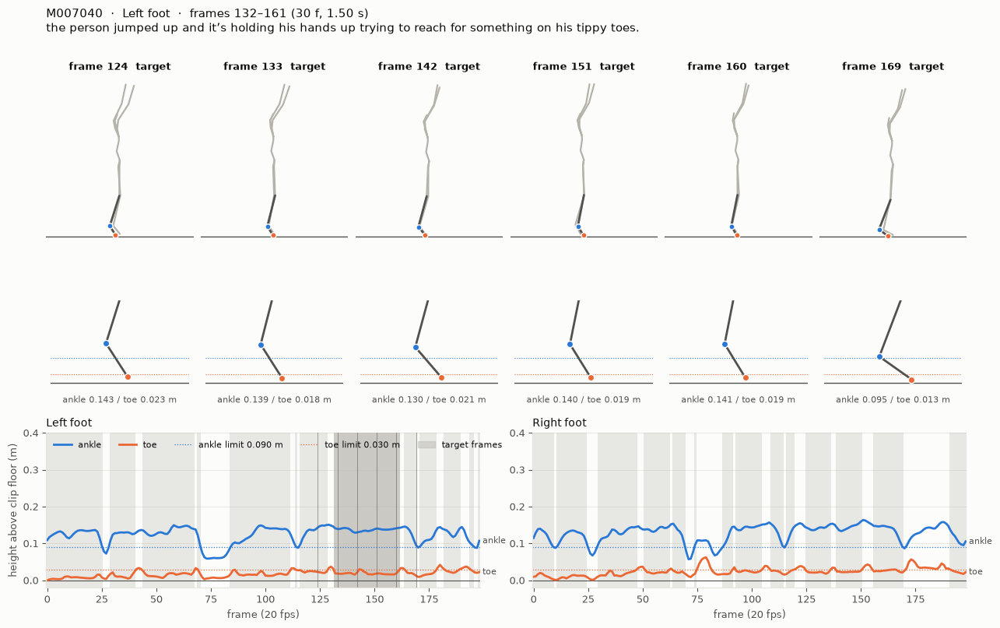

010352 | 발 L | 프레임 98–160 | 63프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
45172,010352,"tiptoe, on toes",L,98,a person stretches calves and tip toes.,0.0914,0.0106,0.0130,height,True
45173,010352,"tiptoe, on toes",L,99,a person stretches calves and tip toes.,0.1022,0.0129,0.0120,height,True
45174,010352,"tiptoe, on toes",L,100,a person stretches calves and tip toes.,0.1115,0.0147,0.0110,height,True
45175,010352,"tiptoe, on toes",L,101,a person stretches calves and tip toes.,0.1195,0.0161,0.0095,height,True
45176,010352,"tiptoe, on toes",L,102,a person stretches calves and tip toes.,0.1258,0.0172,0.0098,height,True
45177,010352,"tiptoe, on toes",L,103,a person stretches calves and tip toes.,0.1300,0.0155,0.0058,height,True
45178,010352,"tiptoe, on toes",L,104,a person stretches calves and tip toes.,0.1324,0.0155,0.0049,height,True
45179,010352,"tiptoe, on toes",L,105,a person stretches calves and tip toes.,0.1343,0.0155,0.0040,height,True
45180,010352,"tiptoe, on toes",L,106,a person stretches calves and tip toes.,0.1357,0.0152,0.0030,height,True
45181,010352,"tiptoe, on toes",L,107,a person stretches calves and tip toes.,0.1360,0.0144,0.0021,height,True


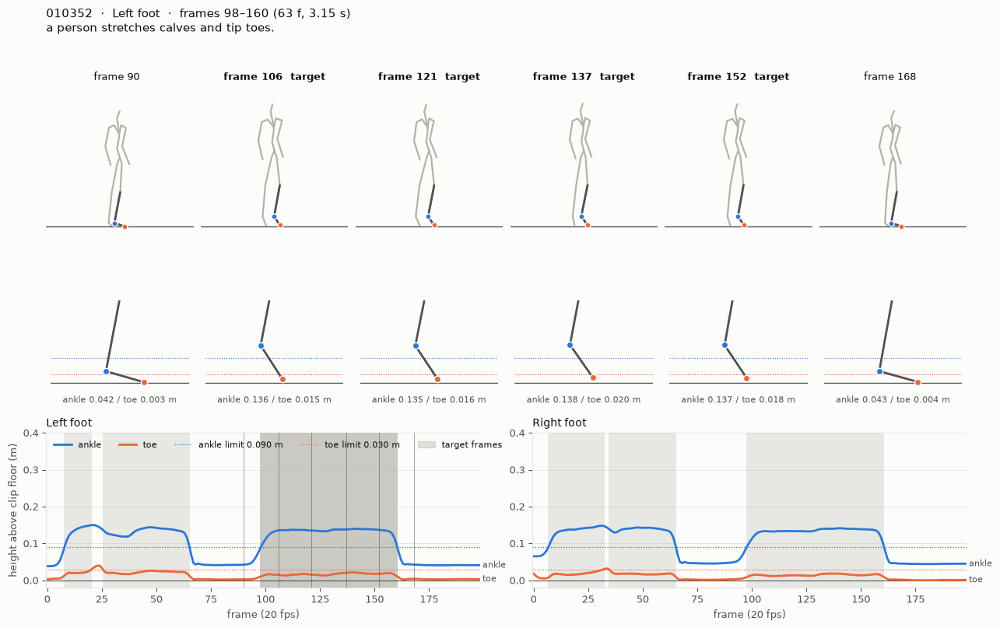

M000726 | 발 L | 프레임 102–171 | 70프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
67082,M000726,"tiptoe, on toes",L,102,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0901,0.0114,0.0058,height,True
67083,M000726,"tiptoe, on toes",L,103,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0931,0.0121,0.0054,height,True
67084,M000726,"tiptoe, on toes",L,104,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0958,0.0125,0.0044,height,True
67085,M000726,"tiptoe, on toes",L,105,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0979,0.0129,0.0030,height,True
67086,M000726,"tiptoe, on toes",L,106,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0987,0.0133,0.0022,height,True
67087,M000726,"tiptoe, on toes",L,107,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0979,0.0134,0.0019,height,True
67088,M000726,"tiptoe, on toes",L,108,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0970,0.0136,0.0015,height,True
67089,M000726,"tiptoe, on toes",L,109,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0971,0.0139,0.0017,height,True
67090,M000726,"tiptoe, on toes",L,110,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.0984,0.0142,0.0022,height,True
67091,M000726,"tiptoe, on toes",L,111,"a standing person rises on their tiptoes, returns to original standing position, takes...",0.1004,0.0146,0.0018,height,True


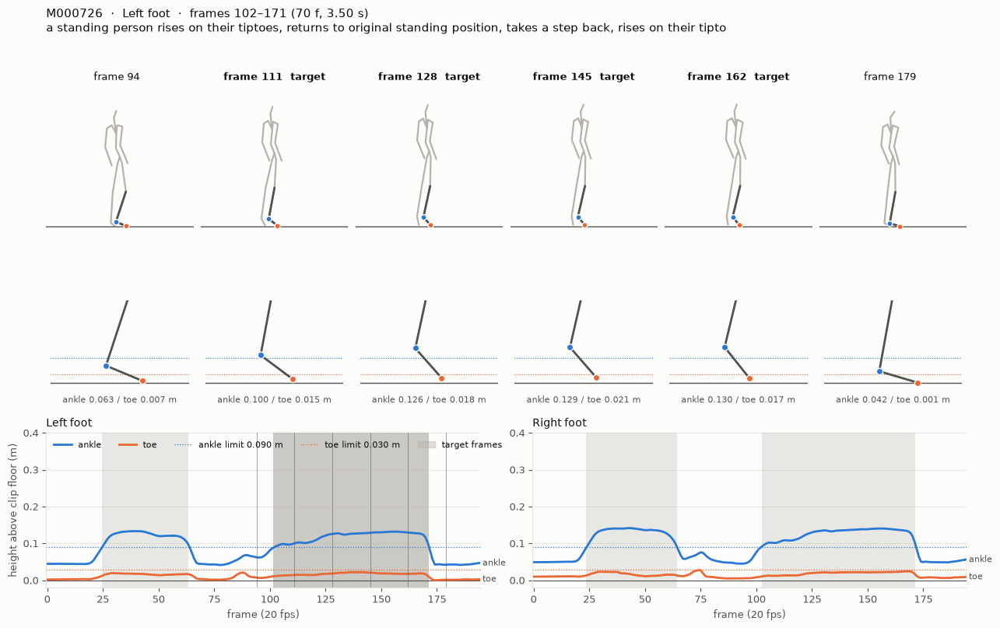

M009074 | 발 R | 프레임 14–42 | 29프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
102160,M009074,on toes,R,14,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.0929,0.0084,0.0190,height,True
102161,M009074,on toes,R,15,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1076,0.0109,0.0195,height,True
102162,M009074,on toes,R,16,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1191,0.0101,0.0169,height,True
102163,M009074,on toes,R,17,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1259,0.0091,0.0070,height,True
102164,M009074,on toes,R,18,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1282,0.0077,0.0021,height,True
102165,M009074,on toes,R,19,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1286,0.0080,0.0015,height,True
102166,M009074,on toes,R,20,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1287,0.0070,0.0039,height,True
102167,M009074,on toes,R,21,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1292,0.0063,0.0033,height,True
102168,M009074,on toes,R,22,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1289,0.0058,0.0016,height,True
102169,M009074,on toes,R,23,the man raises up and down on his toes raises his arms then back up on his toes raise...,0.1278,0.0053,0.0019,height,True


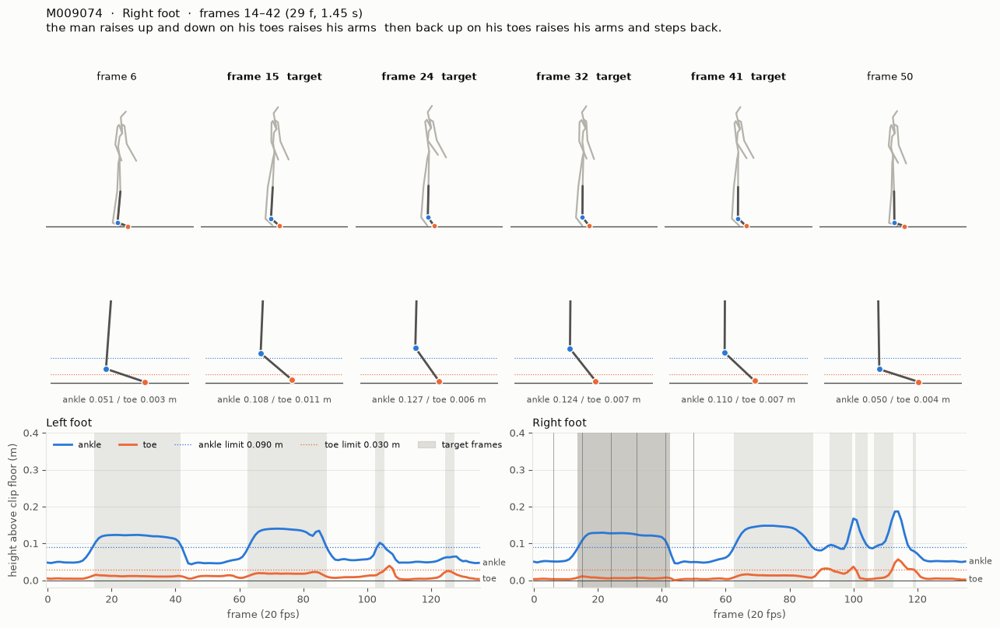

002107 | 발 L | 프레임 19–43 | 25프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
9566,002107,"on toes, stairs",L,19,"a person walks forward, balancing themself on their toes.",0.0936,0.0008,0.0054,height,True
9567,002107,"on toes, stairs",L,20,"a person walks forward, balancing themself on their toes.",0.0978,0.0011,0.0055,height,True
9568,002107,"on toes, stairs",L,21,"a person walks forward, balancing themself on their toes.",0.1018,0.0015,0.0054,height,True
9569,002107,"on toes, stairs",L,22,"a person walks forward, balancing themself on their toes.",0.1059,0.0020,0.0072,height,True
9570,002107,"on toes, stairs",L,23,"a person walks forward, balancing themself on their toes.",0.1107,0.0025,0.0052,height,True
9571,002107,"on toes, stairs",L,24,"a person walks forward, balancing themself on their toes.",0.1138,0.0030,0.0041,height,True
9572,002107,"on toes, stairs",L,25,"a person walks forward, balancing themself on their toes.",0.1157,0.0008,0.0027,height,True
9573,002107,"on toes, stairs",L,26,"a person walks forward, balancing themself on their toes.",0.1173,0.0010,0.0017,height,True
9574,002107,"on toes, stairs",L,27,"a person walks forward, balancing themself on their toes.",0.1185,0.0020,0.0041,height,True
9575,002107,"on toes, stairs",L,28,"a person walks forward, balancing themself on their toes.",0.1190,0.0039,0.0035,height,True


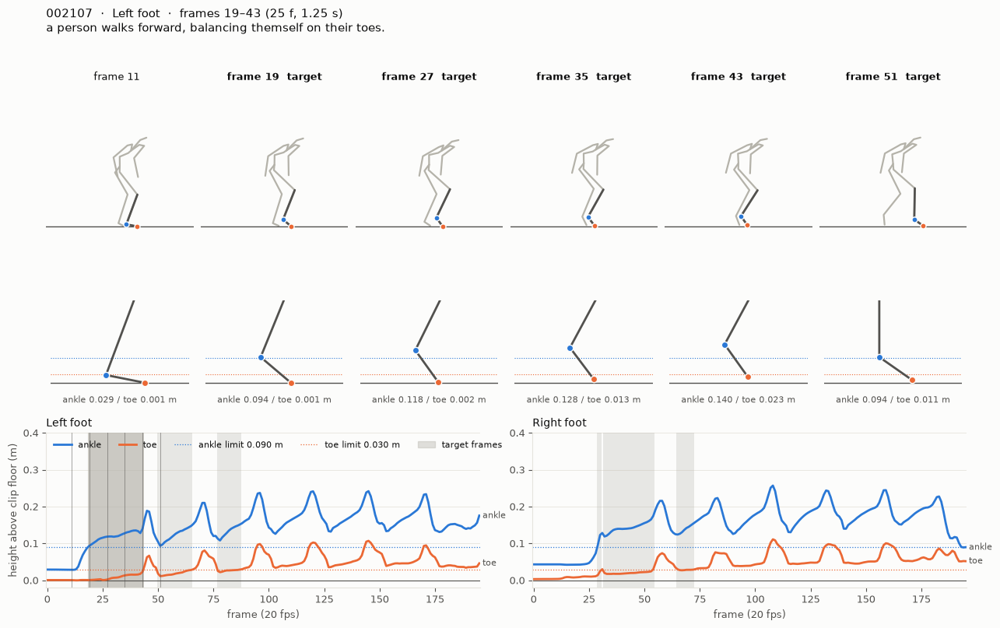

002641 | 발 R | 프레임 26–37 | 12프레임


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
11666,002641,stairs,R,26,"a pa walks down a set of stairs, turns around then walks back up",0.0927,0.0131,0.0101,height,True
11667,002641,stairs,R,27,"a pa walks down a set of stairs, turns around then walks back up",0.1016,0.0150,0.0103,height,True
11668,002641,stairs,R,28,"a pa walks down a set of stairs, turns around then walks back up",0.1104,0.0182,0.0088,height,True
11669,002641,stairs,R,29,"a pa walks down a set of stairs, turns around then walks back up",0.1182,0.0210,0.0060,height,True
11670,002641,stairs,R,30,"a pa walks down a set of stairs, turns around then walks back up",0.1234,0.0236,0.0047,height,True
11671,002641,stairs,R,31,"a pa walks down a set of stairs, turns around then walks back up",0.1271,0.0258,0.0052,height,True
11672,002641,stairs,R,32,"a pa walks down a set of stairs, turns around then walks back up",0.1288,0.0263,0.0020,height,True
11673,002641,stairs,R,33,"a pa walks down a set of stairs, turns around then walks back up",0.1278,0.0257,0.0031,height,True
11674,002641,stairs,R,34,"a pa walks down a set of stairs, turns around then walks back up",0.1250,0.0235,0.0014,height,True
11675,002641,stairs,R,35,"a pa walks down a set of stairs, turns around then walks back up",0.1248,0.0212,0.0143,height,True


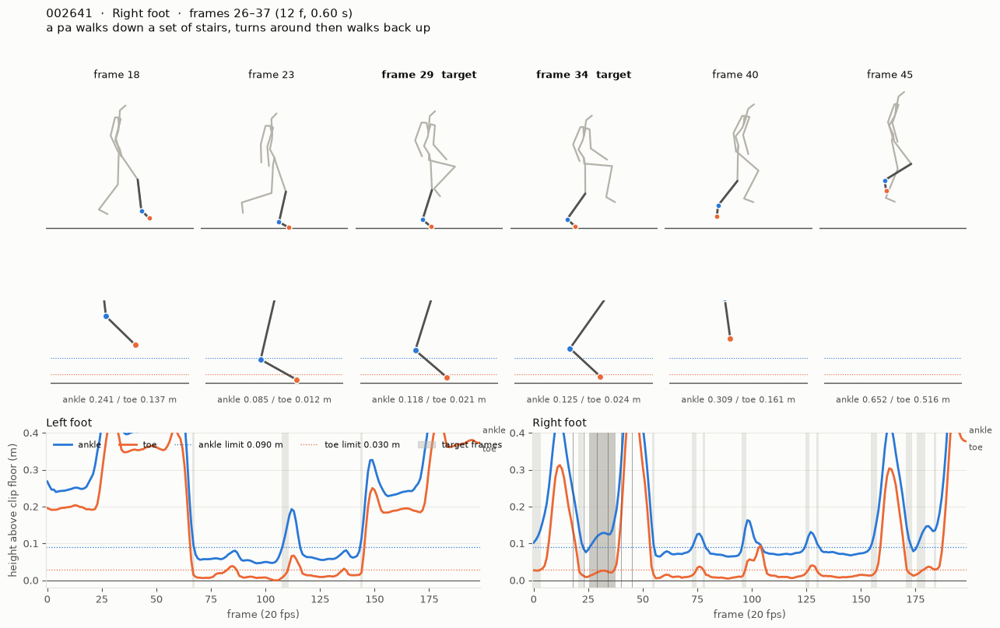

010563 | 발 L | 프레임 0–89 | 90프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
46777,010563,run,L,0,the young boy quickly stands up and runs rapidly forward towards the door.,0.1366,0.0213,0.0048,height,True
46778,010563,run,L,1,the young boy quickly stands up and runs rapidly forward towards the door.,0.1393,0.0221,0.0025,height,True
46779,010563,run,L,2,the young boy quickly stands up and runs rapidly forward towards the door.,0.1416,0.0259,0.0034,height,True
46780,010563,run,L,3,the young boy quickly stands up and runs rapidly forward towards the door.,0.1435,0.0266,0.0022,height,True
46781,010563,run,L,4,the young boy quickly stands up and runs rapidly forward towards the door.,0.1426,0.0249,0.0041,height,True
46782,010563,run,L,5,the young boy quickly stands up and runs rapidly forward towards the door.,0.1418,0.0264,0.0013,height,True
46783,010563,run,L,6,the young boy quickly stands up and runs rapidly forward towards the door.,0.1415,0.0246,0.0069,height,True
46784,010563,run,L,7,the young boy quickly stands up and runs rapidly forward towards the door.,0.1390,0.0263,0.0054,height,True
46785,010563,run,L,8,the young boy quickly stands up and runs rapidly forward towards the door.,0.1343,0.0239,0.0021,height,True
46786,010563,run,L,9,the young boy quickly stands up and runs rapidly forward towards the door.,0.1325,0.0215,0.0021,height,True


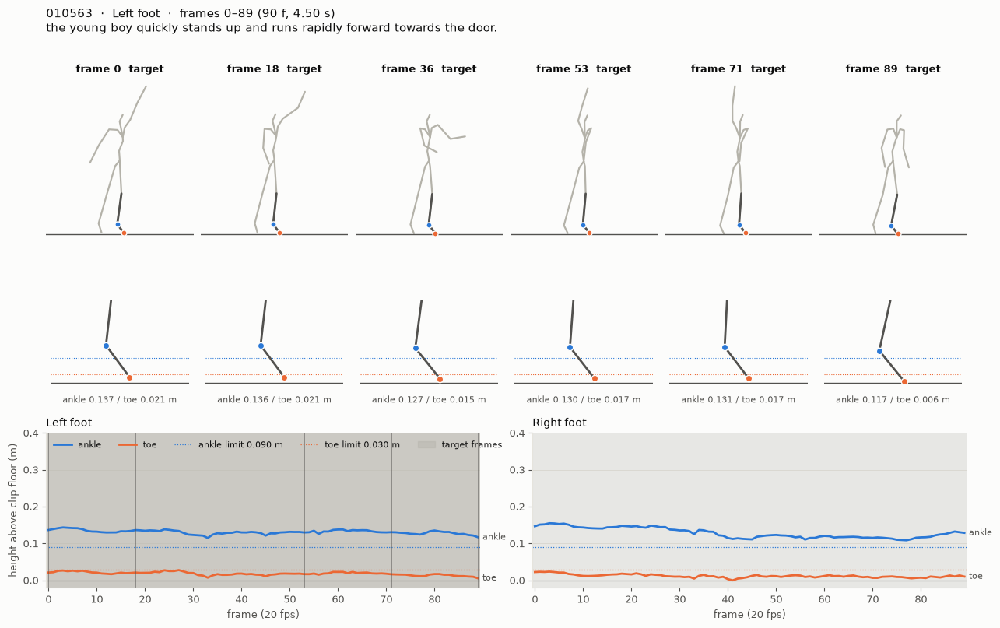

M003076 | 발 R | 프레임 139–158 | 20프레임


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
77062,M003076,run,R,139,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1008,0.0078,0.0199,height,True
77063,M003076,run,R,140,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1170,0.0097,0.0416,height,True
77064,M003076,run,R,141,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1428,0.0128,0.0616,height+motion,True
77065,M003076,run,R,142,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1629,0.0236,0.0799,height+motion,True
77066,M003076,run,R,143,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1587,0.0248,0.1001,height+motion,True
77067,M003076,run,R,144,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1408,0.0224,0.1152,height+motion,True
77068,M003076,run,R,145,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1156,0.0203,0.1200,height+motion,True
77069,M003076,run,R,146,"a person jogs in place and then runs to their right, and then running to the left and ...",0.0996,0.0227,0.0932,height+motion,True
77070,M003076,run,R,147,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1059,0.0258,0.0572,height+motion,True
77071,M003076,run,R,148,"a person jogs in place and then runs to their right, and then running to the left and ...",0.1198,0.0222,0.0189,height,True


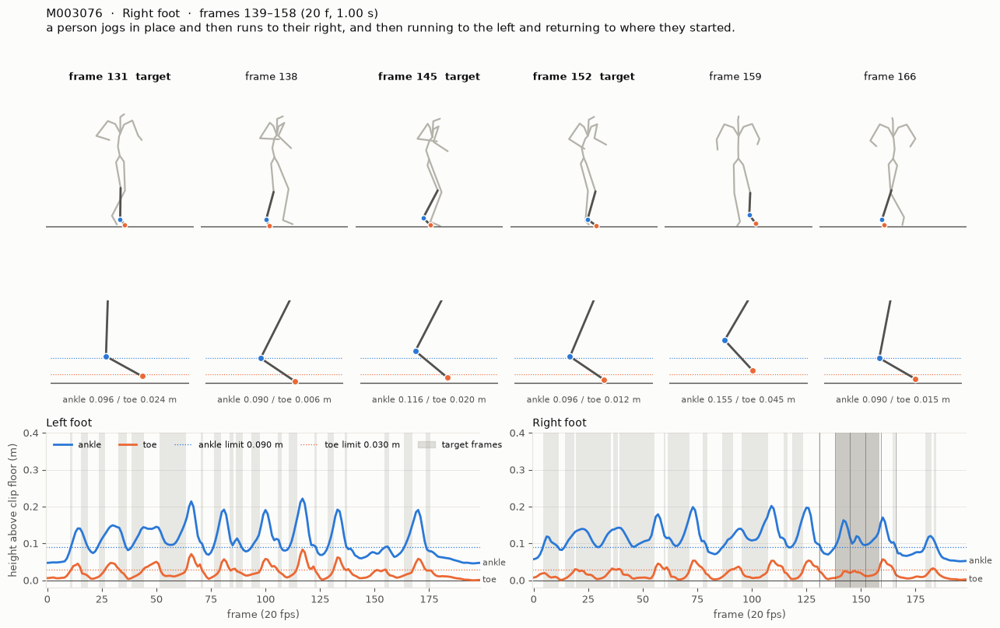

M010238 | 발 L | 프레임 146–153 | 8프레임


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
106874,M010238,jump,L,146,the person is doing jumping jacks,0.1083,0.0213,0.0163,height,True
106875,M010238,jump,L,147,the person is doing jumping jacks,0.0989,0.0106,0.0177,height,True
106876,M010238,jump,L,148,the person is doing jumping jacks,0.1087,0.0114,0.0022,height,True
106877,M010238,jump,L,149,the person is doing jumping jacks,0.1066,0.0094,0.0098,height,True
106878,M010238,jump,L,150,the person is doing jumping jacks,0.0988,0.0061,0.0080,height,True
106879,M010238,jump,L,151,the person is doing jumping jacks,0.1027,0.0065,0.0244,height,True
106880,M010238,jump,L,152,the person is doing jumping jacks,0.1203,0.0124,0.0425,height,True
106881,M010238,jump,L,153,the person is doing jumping jacks,0.1453,0.0240,0.0496,height+motion,True


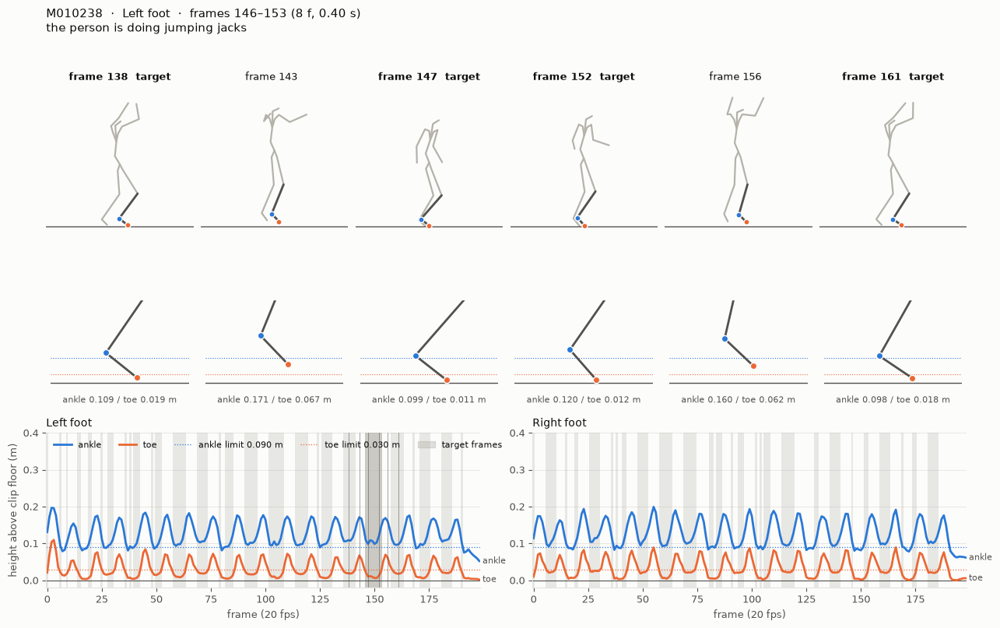

007673 | 발 R | 프레임 81–97 | 17프레임


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
33248,007673,"jump, squat",R,81,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.0928,0.0281,0.0056,height,True
33249,007673,"jump, squat",R,82,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.0927,0.0221,0.0224,height,True
33250,007673,"jump, squat",R,83,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1073,0.0207,0.0165,height,True
33251,007673,"jump, squat",R,84,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1168,0.0205,0.0102,height,True
33252,007673,"jump, squat",R,85,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1219,0.0197,0.0139,height,True
33253,007673,"jump, squat",R,86,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1279,0.0197,0.0105,height,True
33254,007673,"jump, squat",R,87,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1334,0.0211,0.0084,height,True
33255,007673,"jump, squat",R,88,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1387,0.0242,0.0059,height,True
33256,007673,"jump, squat",R,89,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1419,0.0262,0.0046,height,True
33257,007673,"jump, squat",R,90,the figure squats up and down with arms forward with each squat they do a tiny jump as...,0.1425,0.0266,0.0052,height,True


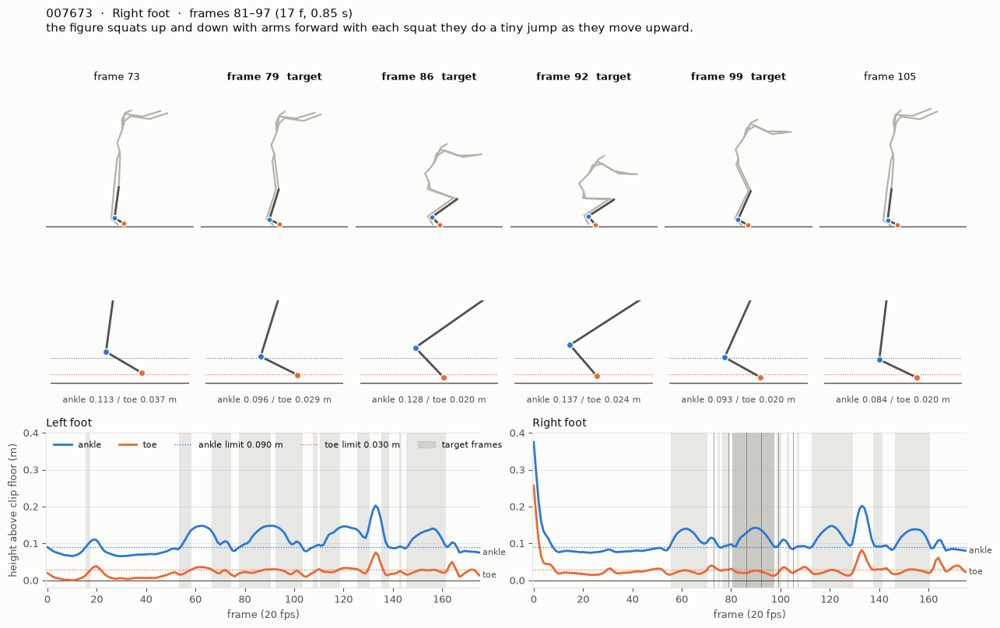

013577 | 발 L | 프레임 0–219 | 220프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
59353,013577,squat,L,0,"a person is squatting, they appear to be cleaning something",0.1054,0.0062,0.0032,height,True
59354,013577,squat,L,1,"a person is squatting, they appear to be cleaning something",0.1052,0.0059,0.0022,height,True
59355,013577,squat,L,2,"a person is squatting, they appear to be cleaning something",0.1046,0.0068,0.0019,height,True
59356,013577,squat,L,3,"a person is squatting, they appear to be cleaning something",0.1051,0.0097,0.0027,height,True
59357,013577,squat,L,4,"a person is squatting, they appear to be cleaning something",0.1035,0.0067,0.0034,height,True
59358,013577,squat,L,5,"a person is squatting, they appear to be cleaning something",0.1037,0.0085,0.0023,height,True
59359,013577,squat,L,6,"a person is squatting, they appear to be cleaning something",0.1059,0.0059,0.0022,height,True
59360,013577,squat,L,7,"a person is squatting, they appear to be cleaning something",0.1049,0.0087,0.0026,height,True
59361,013577,squat,L,8,"a person is squatting, they appear to be cleaning something",0.1061,0.0063,0.0006,height,True
59362,013577,squat,L,9,"a person is squatting, they appear to be cleaning something",0.1066,0.0091,0.0008,height,True


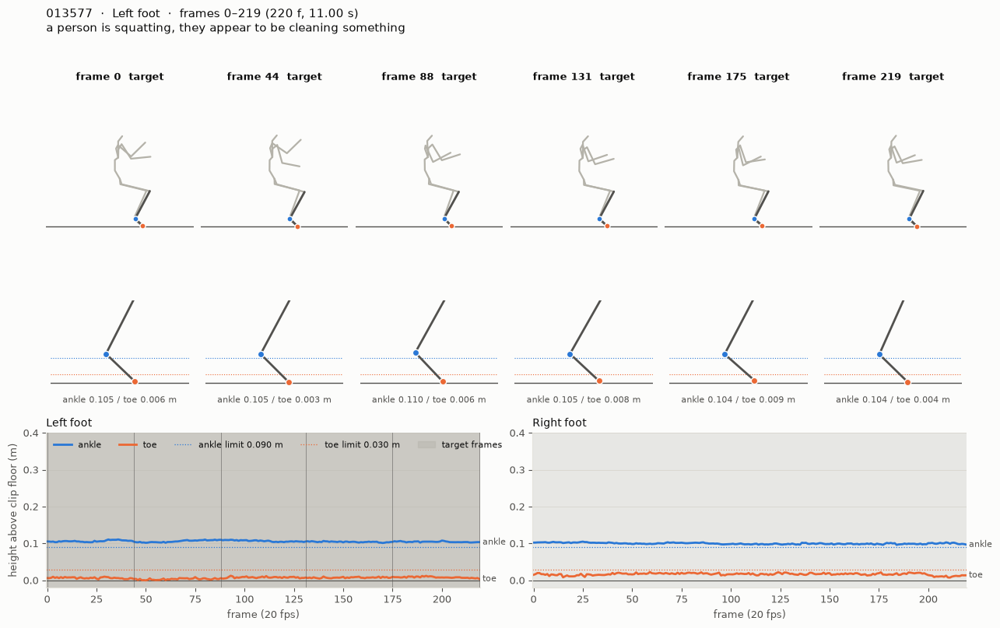

M010541 | 발 L | 프레임 0–210 | 211프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
108560,M010541,squat,L,0,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0948,0.0029,0.0036,height,True
108561,M010541,squat,L,1,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0978,0.0119,0.0031,height,True
108562,M010541,squat,L,2,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0948,0.0042,0.0024,height,True
108563,M010541,squat,L,3,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0966,0.0114,0.0016,height,True
108564,M010541,squat,L,4,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0975,0.0090,0.0031,height,True
108565,M010541,squat,L,5,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0955,0.0055,0.0013,height,True
108566,M010541,squat,L,6,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0944,0.0043,0.0026,height,True
108567,M010541,squat,L,7,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0956,0.0088,0.0013,height,True
108568,M010541,squat,L,8,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0954,0.0081,0.0037,height,True
108569,M010541,squat,L,9,"a person is squat down slowly raising his right arm up, then fully raising up towards ...",0.0961,0.0062,0.0027,height,True


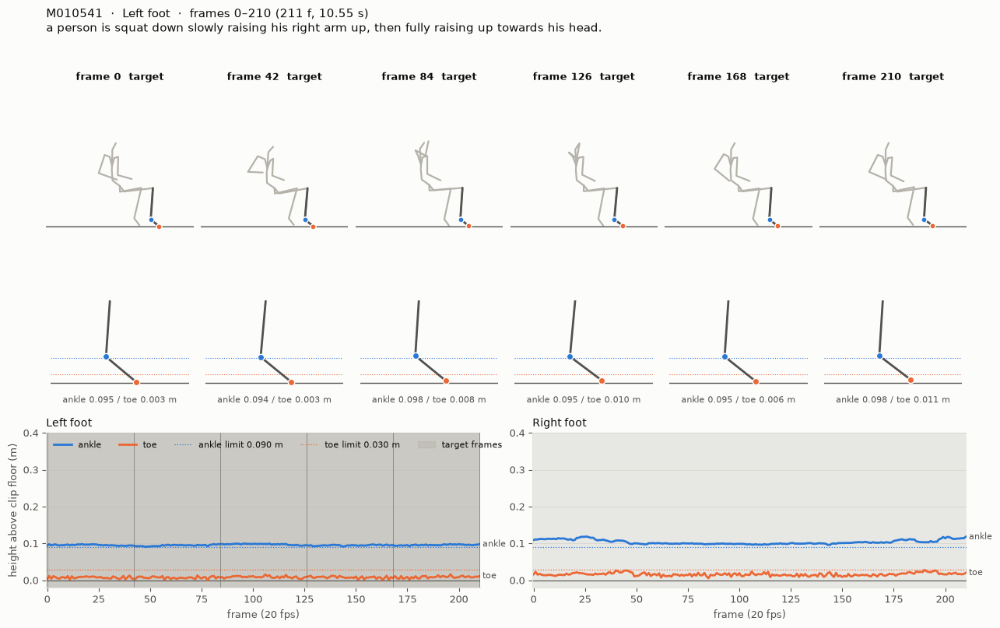

M002171 | 발 R | 프레임 80–160 | 81프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
73281,M002171,kneel,R,80,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1265,0.0279,0.0089,height,True
73282,M002171,kneel,R,81,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1197,0.0218,0.0043,height,True
73283,M002171,kneel,R,82,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1188,0.0189,0.0030,height,True
73284,M002171,kneel,R,83,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1179,0.0149,0.0008,height,True
73285,M002171,kneel,R,84,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1179,0.0148,0.0033,height,True
73286,M002171,kneel,R,85,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1148,0.0129,0.0026,height,True
73287,M002171,kneel,R,86,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1123,0.0117,0.0009,height,True
73288,M002171,kneel,R,87,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1128,0.0130,0.0015,height,True
73289,M002171,kneel,R,88,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1132,0.0140,0.0054,height,True
73290,M002171,kneel,R,89,"a person walks forward at a right angle, slightly turns left, kneels, relaxes and then...",0.1137,0.0150,0.0022,height,True


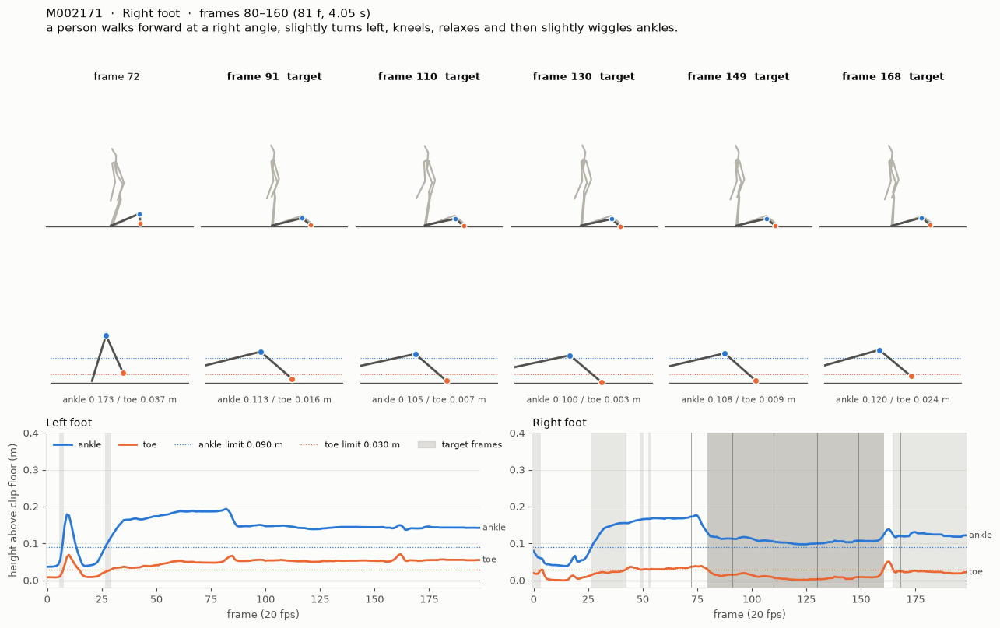

M010053 | 발 R | 프레임 51–85 | 35프레임 (앞 20행만 표시)


,clip,keywords,foot,frame,text,ankle_h,toe_h,ankle_disp,ankle_fail,in_text_span
105972,M010053,kneel,R,51,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.0947,0.0101,0.0070,height,True
105973,M010053,kneel,R,52,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.0999,0.0104,0.0051,height,True
105974,M010053,kneel,R,53,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1040,0.0104,0.0041,height,True
105975,M010053,kneel,R,54,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1071,0.0102,0.0041,height,True
105976,M010053,kneel,R,55,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1094,0.0099,0.0028,height,True
105977,M010053,kneel,R,56,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1109,0.0094,0.0011,height,True
105978,M010053,kneel,R,57,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1119,0.0087,0.0010,height,True
105979,M010053,kneel,R,58,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1126,0.0081,0.0015,height,True
105980,M010053,kneel,R,59,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1133,0.0077,0.0012,height,True
105981,M010053,kneel,R,60,"a person walks forward and kneels down, stands back up and kneels down again, and begi...",0.1139,0.0076,0.0011,height,True


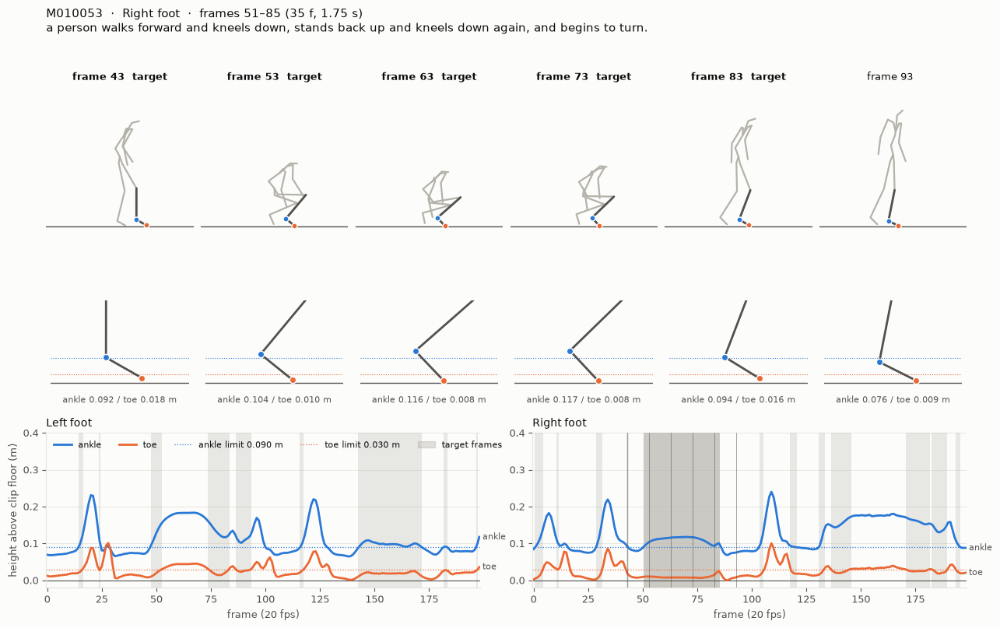

In [6]:
# 키워드별로 순위 상위 클립 시각화. 여러 키워드에 걸린 클립은 한 번만 표시
rank_order = rank['clip'].tolist()
seen = set()
for kw, kw_clips in keyword_clips.items():
    members = set(kw_clips)
    ordered = [c for c in rank_order if c in members and base_name(c) not in seen]
    display(HTML(f'<h3>{kw}</h3>'))
    if not ordered:
        print('대상 프레임이 있는 클립 없음')
        continue
    visualize_ranked(ordered, joints, matched_captions, frame_df, VIS_PER_KEYWORD, VIS_RANK_START, seen)

## 4. 특정 클립 보기

맨 위 셀의 `INSPECT_CLIP`에 표에서 고른 클립 이름을 넣고 실행합니다.

In [7]:
# 표에서 고른 클립 한 개를 시각화
if INSPECT_CLIP is None:
    print('INSPECT_CLIP이 None이라 건너뜀')
else:
    if INSPECT_CLIP not in joints:
        joints.update(load_joints([INSPECT_CLIP]))
        matched_captions[INSPECT_CLIP] = load_captions(INSPECT_CLIP)
    visualize_clip(INSPECT_CLIP, joints, matched_captions,
                   build_frame_table([INSPECT_CLIP], joints, matched_captions))

INSPECT_CLIP이 None이라 건너뜀
